In [1]:
import torch
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("08-seismic_activity_svm.csv")

In [3]:
df.head()

,underground_wave_energy,vibration_axis_variation,seismic_event_detected
0,9.539392,-3.000000,0
1,9.558241,-2.939394,0
2,9.576669,-2.878788,0
3,9.594678,-2.818182,0
4,9.612272,-2.757576,0


In [5]:
df.describe()

,underground_wave_energy,vibration_axis_variation,seismic_event_detected
count,400.000000,4.000000e+02,400.000000
mean,0.000000,8.881784e-18,0.500000
std,7.719350,1.751650e+00,0.500626
min,-9.999954,-3.000000e+00,0.000000
25%,-6.134779,-1.500000e+00,0.000000
50%,0.000000,0.000000e+00,0.500000
75%,6.134779,1.500000e+00,1.000000
max,9.999954,3.000000e+00,1.000000


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 3 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   underground_wave_energy   400 non-null    float64
 1   vibration_axis_variation  400 non-null    float64
 2   seismic_event_detected    400 non-null    int64  
dtypes: float64(2), int64(1)
memory usage: 9.5 KB


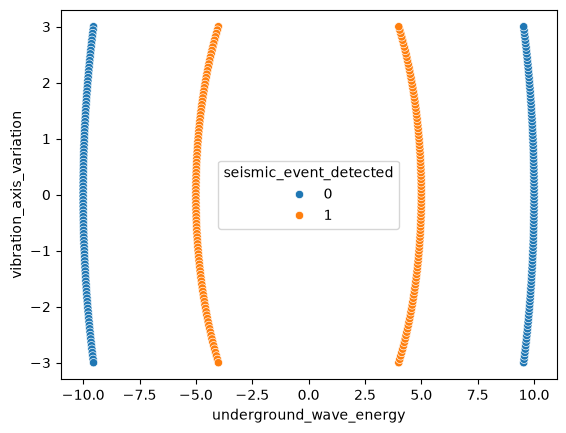

In [9]:
sns.scatterplot(x=df['underground_wave_energy'],y=df['vibration_axis_variation'],hue=df['seismic_event_detected'])
plt.show()

In [10]:
X = df[["underground_wave_energy", "vibration_axis_variation"]].values
y = df["seismic_event_detected"].values 

In [11]:
y

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,

In [12]:
from sklearn.model_selection import train_test_split

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [14]:
X_train = torch.tensor(X_train, dtype=torch.float32)   # shape: (800, 2)
X_test  = torch.tensor(X_test,  dtype=torch.float32)   # shape: (200, 2)

y_train = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)  # shape: (800, 1)
y_test  = torch.tensor(y_test,  dtype=torch.float32).unsqueeze(1)  # shape: (200, 1)

In [15]:
print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

torch.Size([320, 2]) torch.Size([320, 1])
torch.Size([80, 2]) torch.Size([80, 1])


In [16]:
from torch import nn

In [17]:
class ClassificationModel(nn.Module):
    def __init__(self):
        super().__init__()
       
        self.layer_1 = nn.Linear(in_features=2, out_features=5) 
        self.layer_2 = nn.Linear(in_features=5, out_features=1) 
    def forward(self, x):
      
        return self.layer_2(self.layer_1(x)) 

In [18]:
model_0 = ClassificationModel()

In [19]:
loss_fn = nn.BCEWithLogitsLoss()

optimizer = torch.optim.SGD(params=model_0.parameters(), lr=0.01)

In [20]:
def calculate_accuracy(y_test, y_pred):
    correct = torch.eq(y_test, y_pred).sum().item() 
    accuracy = (correct / len(y_pred)) * 100 
    return accuracy

In [21]:
y_logits = model_0(X_test)[:5]

In [22]:
y_logits

tensor([[-2.0245],
        [-3.6161],
        [-5.3424],
        [-2.0619],
        [-6.4100]], grad_fn=<SliceBackward0>)

In [26]:
y_pred_probs = torch.sigmoid(y_logits)

In [27]:
y_pred_probs

# if they are above 0.5 then we can call it 1 and if they are less 0
y_preds = torch.round(y_pred_probs)

In [28]:
y_preds

tensor([[0.],
        [0.],
        [0.],
        [0.],
        [0.]], grad_fn=<RoundBackward0>)

In [29]:
y_preds.squeeze()

tensor([0., 0., 0., 0., 0.], grad_fn=<SqueezeBackward0>)

In [30]:
torch.manual_seed(42)
epochs = 100

for epoch in range(epochs):
    
    model_0.train()

    
    y_logits = model_0(X_train) 
    y_pred = torch.round(torch.sigmoid(y_logits)) # logits -> pred probs -> pred labls
  
    
    loss = loss_fn(y_logits,
                   y_train) 
    acc = calculate_accuracy(y_test=y_train, 
                      y_pred=y_pred) 

    
    optimizer.zero_grad()


    loss.backward()

    
    optimizer.step()

    
    model_0.eval()
    with torch.inference_mode():
        
        test_logits = model_0(X_test)
        test_pred = torch.round(torch.sigmoid(test_logits))
       
        test_loss = loss_fn(test_logits,
                            y_test)
        test_acc = calculate_accuracy(y_test=y_test,
                               y_pred=test_pred)

    if epoch % 5 == 0:
        print(f"Epoch: {epoch} | Loss: {loss:.5f}, Accuracy: {acc:.2f}% | Test loss: {test_loss:.5f}, Test acc: {test_acc:.2f}%")

Epoch: 0 | Loss: 1.95801, Accuracy: 48.75% | Test loss: 1.55967, Test acc: 55.00%
Epoch: 5 | Loss: 1.37069, Accuracy: 48.12% | Test loss: 1.09549, Test acc: 55.00%
Epoch: 10 | Loss: 1.02799, Accuracy: 43.44% | Test loss: 0.84164, Test acc: 55.00%
Epoch: 15 | Loss: 0.85351, Accuracy: 38.12% | Test loss: 0.72750, Test acc: 50.00%
Epoch: 20 | Loss: 0.77507, Accuracy: 34.69% | Test loss: 0.68714, Test acc: 51.25%
Epoch: 25 | Loss: 0.74196, Accuracy: 37.81% | Test loss: 0.67757, Test acc: 48.75%
Epoch: 30 | Loss: 0.72779, Accuracy: 47.81% | Test loss: 0.67826, Test acc: 55.00%
Epoch: 35 | Loss: 0.72112, Accuracy: 48.75% | Test loss: 0.68137, Test acc: 55.00%
Epoch: 40 | Loss: 0.71740, Accuracy: 48.75% | Test loss: 0.68440, Test acc: 55.00%
Epoch: 45 | Loss: 0.71489, Accuracy: 48.75% | Test loss: 0.68679, Test acc: 55.00%
Epoch: 50 | Loss: 0.71291, Accuracy: 48.75% | Test loss: 0.68857, Test acc: 55.00%
Epoch: 55 | Loss: 0.71123, Accuracy: 48.75% | Test loss: 0.68990, Test acc: 55.00%
Epoch:

In [31]:
	
import numpy as np
def plot_linear_decision_boundary(model, X, y):

  
    W1 = model.layer_1.weight.detach().numpy()       
    b1 = model.layer_1.bias.detach().numpy()         
    W2 = model.layer_2.weight.detach().numpy()       
    b2 = model.layer_2.bias.detach().numpy()[0]      

    
    W_eff = W2 @ W1  
    w1, w2 = W_eff[0] 

   
    b_eff = (W2 @ b1)[0] + b2

   
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    xs = np.linspace(x_min, x_max, 200)

 
    ys = -(w1 * xs + b_eff) / w2

   
    plt.scatter(X[:, 0], X[:, 1], c=y.squeeze(), cmap=plt.cm.RdYlBu, s=40)
    plt.plot(xs, ys, "k-", linewidth=3)
    plt.xlabel("subject_formality_score")
    plt.ylabel("sender_relationship_score")
    plt.xlim(x_min, x_max)
    plt.ylim(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5)

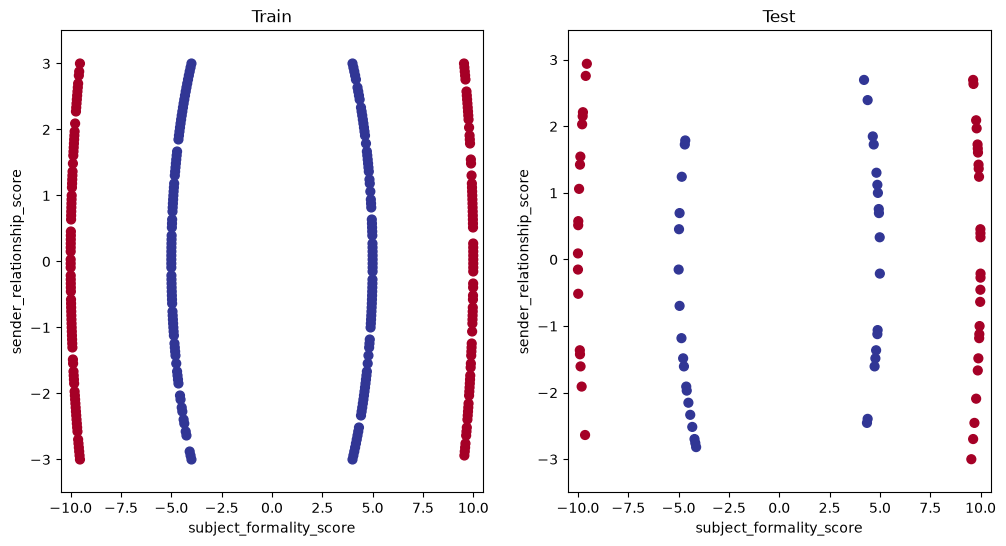

In [32]:
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.title("Train")
plot_linear_decision_boundary(model_0, X_train, y_train)

plt.subplot(1, 2, 2)
plt.title("Test")
plot_linear_decision_boundary(model_0, X_test, y_test)

plt.show()